

| Model | Fitur |
|---|---|
| **A** | 7 fitur kurs (lag 1-5, rolling mean/std 5 hari) |
| **B** | A + 16 fitur lexicon (VADER 6 + LM judul 5 + LM isi 5) |
| **C-static** | A + embedding statis: GloVe, Word2Vec, FastText (dirata-rata per artikel → per hari → PCA) |

**Aturan perbandingan yang adil:** split sama (836/178/180), blok fitur teks saja yang berganti, semua scaler/PCA/IDF/Word2Vec dilatih **hanya di data train**.

## 0. Setup

In [1]:
import sys, re, json, warnings, time
sys.dont_write_bytecode = True          # jangan buat __pycache__ di src/
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef

warnings.filterwarnings("ignore")
sys.path.append("../src")
from eval_utils import evaluate, naive_baselines   # metrik bersama tim

EXPORT_DIR = Path("../data/export")
SEED = 42
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)

## 1. Muat data (read-only) dan cek konsistensi

`prices_daily` sudah berisi fitur kurs, target, dan kolom `split`. `sentiment_daily` berisi 16 fitur lexicon.
`articles` berisi teks asli (`title`, `full_text`) dan `aligned_trading_date` (hari trading yang dipakai untuk menggabungkan berita ke harga).

In [2]:
articles = pd.read_parquet(EXPORT_DIR / "articles.parquet").sort_values("article_id").reset_index(drop=True)
prices   = pd.read_parquet(EXPORT_DIR / "prices_daily.parquet")
sent     = pd.read_parquet(EXPORT_DIR / "sentiment_daily.parquet")
splits   = json.loads((EXPORT_DIR / "splits.json").read_text())

KURS_COLS = ["kurs_lag1", "kurs_lag2", "kurs_lag3", "kurs_lag4", "kurs_lag5",
             "kurs_roll_mean5", "kurs_roll_std5"]
LEX_COLS = [c for c in sent.columns if c not in ("date", "news_count")]
assert len(KURS_COLS) == 7 and len(LEX_COLS) == 16

daily = (prices.merge(sent[["date", "news_count"] + LEX_COLS], on="date", how="left")
               .sort_values("date").reset_index(drop=True))
assert daily[LEX_COLS].notna().all().all(), "ada tanggal harga tanpa baris sentimen"

for s in ("train", "val", "test"):
    assert (daily["split"] == s).sum() == splits[s]["n"], f"jumlah baris {s} tidak cocok dengan splits.json"
tr = (daily["split"] == "train").to_numpy()
va = (daily["split"] == "val").to_numpy()
te = (daily["split"] == "test").to_numpy()
y  = daily["target"].to_numpy()

print("baris per split:", tr.sum(), va.sum(), te.sum())
print("share target naik (>0)  train/val/test:",
      [round(float((y[m] > 0).sum() / (y[m] != 0).sum()), 4) for m in (tr, va, te)])

baris per split: 836 178 180
share target naik (>0)  train/val/test: [0.5621, 0.5341, 0.5909]


### Pemetaan artikel ke split
Artikel masuk split berdasarkan `aligned_trading_date`. Artikel yang tanggalnya tidak ada di `prices_daily` (mis. hari yang dibuang di batas split) tidak dipakai.

In [3]:
date2split = dict(zip(daily["date"], daily["split"]))
articles["split"] = articles["aligned_trading_date"].map(date2split)
print(articles["split"].value_counts(dropna=False).to_string())

split
train    2489
test     1220
val       619
NaN         4


## 2. Tokenisasi

Teks = `title. full_text` (teks asli, sama dengan resep `title_text` di `make_embeddings.py`). Huruf kecil, hanya token alfabet.
Tidak membuang stopword: pembobotan IDF di bawah yang akan menurunkan bobot kata umum.

In [4]:
TOKEN_RE = re.compile(r"[a-z]+")
articles["text_raw"] = articles["title"].fillna("").str.strip() + ". " + articles["full_text"].fillna("").str.strip()
articles["tokens"] = articles["text_raw"].str.lower().map(TOKEN_RE.findall)

corp_train = articles.loc[articles["split"] == "train", "tokens"].tolist()   # korpus TRAIN saja
n_tok = articles["tokens"].map(len)
print(f"artikel: {len(articles)} | token/artikel rata-rata {n_tok.mean():.0f} (median {n_tok.median():.0f})")
print(f"artikel train: {len(corp_train)} | total token train: {sum(map(len, corp_train)):,}")

# IDF dari artikel TRAIN saja
df_cnt = Counter(w for toks in corp_train for w in set(toks))
N_TRAIN = len(corp_train)
def idf(w):
    return np.log((N_TRAIN + 1) / (df_cnt.get(w, 0) + 1)) + 1.0

artikel: 4332 | token/artikel rata-rata 798 (median 709)
artikel train: 2489 | total token train: 2,061,123


## 3. Tiga sumber embedding statis

| Nama | Sumber | Catatan |
|---|---|---|
| **GloVe** | `glove-wiki-gigaword-100` (pretrained, Wikipedia+Gigaword, 100d) | Bukan teks berita kita; kosakata tetap. Kata di luar kosakata dilewati. |
| **Word2Vec** | dilatih dari awal pada artikel **train** (skip-gram, 100d) | Memuat kosakata domain geopolitik/forex, tapi korpus kecil (~2,5 juta token). |
| **FastText** | dilatih dari awal pada artikel **train** (100d, subword) | Kata jarang/typo tetap punya vektor lewat n-gram karakter. |

Word2Vec/FastText dilatih tanpa label, tapi hanya dari artikel train supaya periode val/test tidak ikut membentuk representasi.

In [5]:
import logging
logging.disable(logging.CRITICAL)
import gensim.downloader as api
from gensim.models import Word2Vec, FastText

t0 = time.time()
glove = api.load("glove-wiki-gigaword-100")          # ~130 MB, diunduh sekali lalu di-cache
print(f"GloVe: {len(glove.key_to_index):,} kata, dim {glove.vector_size}  ({time.time()-t0:.0f}s)")

t0 = time.time()
w2v = Word2Vec(corp_train, vector_size=100, window=5, min_count=5, sg=1, epochs=10,
               workers=1, seed=SEED)
print(f"Word2Vec: {len(w2v.wv.key_to_index):,} kata ({time.time()-t0:.0f}s)")

t0 = time.time()
ft = FastText(corp_train, vector_size=100, window=5, min_count=5, sg=1, epochs=10,
              workers=1, seed=SEED)
print(f"FastText: {len(ft.wv.key_to_index):,} kata ({time.time()-t0:.0f}s)")

GloVe: 400,000 kata, dim 100  (27s)


Word2Vec: 14,862 kata (87s)


FastText: 14,862 kata (154s)


Cek cepat kewarasan: tetangga terdekat harus masuk akal secara semantik.

In [6]:
for name, kv in [("GloVe", glove), ("Word2Vec (train)", w2v.wv), ("FastText (train)", ft.wv)]:
    print(f"== {name}")
    for q in ["inflation", "sanctions", "oil"]:
        if q in kv.key_to_index:
            print(f"  {q:10s}", [w for w, _ in kv.most_similar(q, topn=6)])

== GloVe
  inflation  ['rate', 'rates', 'unemployment', 'inflationary', 'growth', 'deflation']
  sanctions  ['embargo', 'imposed', 'sanction', 'impose', 'lifting', 'restrictions']
  oil        ['petroleum', 'crude', 'gas', 'fuel', 'energy', 'supply']
== Word2Vec (train)
  inflation  ['tame', 'stubbornly', 'cpi', 'sticky', 'uncomfortably', 'inflationary']
  sanctions  ['punitive', 'imposing', 'imposed', 'raft', 'crippling', 'impose']
  oil        ['crude', 'seaborne', 'energy', 'brent', 'undersupply', 'soybean']
== FastText (train)
  inflation  ['inflationary', 'deflation', 'disinflation', 'inflated', 'stagflation', 'stubbornly']
  sanctions  ['sanction', 'sanctionson', 'sanctionsagainst', 'sanctioning', 'imposes', 'sanctioned']
  oil        ['crude', 'brentcrude', 'brent', 'rude', 'energy', 'gas']


## 4. Dari kata → artikel → hari → fitur

1. **Artikel:** rata-rata vektor kata (`mean`) atau rata-rata berbobot IDF (`idf`).
2. **Hari:** rata-rata semua artikel pada `aligned_trading_date` yang sama.
3. **Hari tanpa berita:** tidak punya vektor → diisi 0 pada ruang PCA (= vektor rata-rata, "netral").
4. **PCA** (20 komponen) di-fit **hanya pada hari train yang punya berita**, lalu dipakai untuk semua hari. Komponen pertama k dipakai sebagai fitur (k = 5, 10, 20).

Dengan ~836 baris train, 300+ dimensi mentah akan overfit, jadi reduksi dimensi wajib.

In [7]:
KS = (5, 10, 20)

def article_embeddings(token_lists, kv, use_idf, subword):
    """Rata-rata vektor kata per artikel. subword=True (FastText): semua kata punya vektor."""
    vocab = {w for toks in token_lists for w in toks}
    cache = {w: kv[w] for w in vocab if subword or w in kv.key_to_index}
    out = np.zeros((len(token_lists), kv.vector_size), dtype=np.float64)
    ok = np.zeros(len(token_lists), dtype=bool)
    hit = tot = 0
    for i, toks in enumerate(token_lists):
        vs = [cache[w] for w in toks if w in cache]
        tot += len(toks); hit += len(vs)
        if vs:
            ws = [idf(w) for w in toks if w in cache] if use_idf else None
            out[i] = np.average(vs, axis=0, weights=ws); ok[i] = True
    return out, ok, hit / tot

def static_features(kv, use_idf, subword, kmax=max(KS)):
    A, ok, coverage = article_embeddings(articles["tokens"].tolist(), kv, use_idf, subword)
    keep = ok & articles["split"].notna().to_numpy()
    emb = pd.DataFrame(A[keep]); emb["date"] = articles.loc[keep, "aligned_trading_date"].to_numpy()
    d = emb.groupby("date").mean().reindex(daily["date"])
    has = d.notna().all(axis=1).to_numpy()
    D = d.to_numpy(dtype=float)
    fit_rows = tr & has                                   # PCA hanya dari TRAIN
    pca = PCA(n_components=kmax, random_state=SEED).fit(D[fit_rows])
    Z = np.zeros((len(daily), kmax)); Z[has] = pca.transform(D[has])
    info = dict(coverage=coverage, news_days=int(has.sum()), evr=float(pca.explained_variance_ratio_.sum()))
    return {k: Z[:, :k] for k in KS}, info

SOURCES = {"GloVe": (glove, False), "Word2Vec": (w2v.wv, False), "FastText": (ft.wv, True)}
STATIC = {}      # (sumber, bobot, k) -> matriks fitur
INFO = []
for src, (kv, subword) in SOURCES.items():
    for weighting in ("mean", "idf"):
        Zs, info = static_features(kv, weighting == "idf", subword)
        for k, Z in Zs.items():
            STATIC[(src, weighting, k)] = Z
        INFO.append(dict(sumber=src, bobot=weighting, **info))
info_df = pd.DataFrame(INFO)
info_df.columns = ["sumber", "bobot", "cakupan_token", "hari_ada_berita", "EVR_20_komponen"]
info_df

,sumber,bobot,cakupan_token,hari_ada_berita,EVR_20_komponen
0,GloVe,mean,0.982981,1073,0.864393
1,GloVe,idf,0.982981,1073,0.832843
2,Word2Vec,mean,0.968192,1073,0.859438
3,Word2Vec,idf,0.968192,1073,0.866178
4,FastText,mean,1.000000,1073,0.859822
5,FastText,idf,1.000000,1073,0.863612


## 5. Protokol evaluasi

- Scaler dilatih di train; model di-fit di train; skor dilaporkan untuk **val** dan **test**. Pilih/bandingkan memakai **val**, test hanya konfirmasi.
- Tiga model dengan hyperparameter tetap (belum di-tuning): Ridge, Random Forest, Gradient Boosting. RF/GB dirata-ratakan atas 3 seed supaya perbedaan kecil bukan hanya noise.
- Metrik: `evaluate()` dari `eval_utils` (MAE, MSE, RMSE, DirAcc, PredStd) **ditambah** BalAcc dan MCC arah, karena DirAcc saja menyesatkan bila model menebak konstan.
- Pembanding tanpa model: Prediksi 0, Return kemarin, dan Konstan (rata-rata target train).

In [8]:
MODELS = {
    "Ridge": lambda s: Ridge(alpha=10.0),
    "RandForest": lambda s: RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                                  max_features=0.5, n_jobs=-1, random_state=s),
    "GradBoost": lambda s: GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.03,
                                                     subsample=0.8, random_state=s),
}
SEEDS = (0, 1, 2)

def direction_metrics(y_true, y_pred):
    m = y_true != 0
    t, p = y_true[m] > 0, y_pred[m] > 0
    return {"BalAcc": balanced_accuracy_score(t, p), "MCC": matthews_corrcoef(t, p)}

def fit_predict(X):
    sc = StandardScaler().fit(X[tr])                      # scaler dari TRAIN saja
    Xs = sc.transform(X)
    preds = {}
    for name, make in MODELS.items():
        seeds = (0,) if name == "Ridge" else SEEDS
        preds[name] = np.mean([make(s).fit(Xs[tr], y[tr]).predict(Xs) for s in seeds], axis=0)
    return preds

rows = []
def run(set_name, X):
    for mname, p in fit_predict(X).items():
        for sp, mask in (("val", va), ("test", te)):
            r = evaluate(y[mask], p[mask]); r.update(direction_metrics(y[mask], p[mask]))
            rows.append(dict(set=set_name, model=mname, split=sp, **r))

# Pembanding tanpa model
ret_today = daily["ret"].to_numpy()
base_rows = []
for sp, mask in (("val", va), ("test", te)):
    nb = naive_baselines(y[mask], ret_today[mask])
    nb["Konstan (mean train)"] = evaluate(y[mask], np.full(mask.sum(), y[tr].mean()))
    preds = {"Prediksi 0": np.zeros(mask.sum()), "Return kemarin": ret_today[mask],
             "Konstan (mean train)": np.full(mask.sum(), y[tr].mean())}
    for name, r in nb.items():
        r = dict(r); r.update(direction_metrics(y[mask], preds[name]))
        base_rows.append(dict(set=name, model="-", split=sp, **r))

# Model A, B, dan C-static
run("A  kurs", daily[KURS_COLS].to_numpy())
run("B  kurs+lexicon", daily[KURS_COLS + LEX_COLS].to_numpy())
for (src, weighting, k), Z in STATIC.items():
    run(f"C  kurs+{src}-{weighting} k={k}", np.hstack([daily[KURS_COLS].to_numpy(), Z]))

res = pd.DataFrame(rows)
base = pd.DataFrame(base_rows)
print("selesai:", res["set"].nunique(), "set fitur x", res["model"].nunique(), "model")

selesai: 20 set fitur x 3 model


## 6. Hasil

### 6.1 Pembanding tanpa model
Perhatikan `Prediksi 0`: DirAcc = 0 hanyalah artefak (sign 0 selalu salah). Pembanding yang adil untuk arah adalah `Konstan`.

In [9]:
cols = ["MAE", "RMSE", "DirAcc", "BalAcc", "MCC"]
base.pivot(index="set", columns="split", values=cols).round(5)

MAE              RMSE            DirAcc          BalAcc               MCC         
split                    test      val     test      val     test      val   test      val     test      val
set                                                                                                         
Konstan (mean train)  0.00218  0.00246  0.00289  0.00338  0.59091  0.53409  0.500  0.50000  0.00000  0.00000
Prediksi 0            0.00221  0.00247  0.00291  0.00338  0.00000  0.00000  0.500  0.50000  0.00000  0.00000
Return kemarin        0.00308  0.00347  0.00398  0.00461  0.54545  0.50568  0.539  0.50908  0.07754  0.01816

### 6.2 Rata-rata 3 model per set fitur
`ΔRMSE%` = selisih terhadap Model A pada split yang sama (negatif = lebih baik dari A). Diurutkan menurut RMSE **val**.

In [10]:
mean_tbl = res.groupby(["set", "split"])[["RMSE", "DirAcc", "BalAcc", "MCC"]].mean().unstack("split")
a_rmse = mean_tbl.loc["A  kurs", "RMSE"]
for sp in ("val", "test"):
    mean_tbl[("dRMSE%", sp)] = (mean_tbl[("RMSE", sp)] / a_rmse[sp] - 1) * 100
mean_tbl = mean_tbl.sort_values(("RMSE", "val"))
mean_tbl.round(5)

RMSE            DirAcc            BalAcc               MCC            dRMSE%         
split                          test      val     test      val     test      val     test      val      val     test
set                                                                                                                 
C  kurs+FastText-idf k=20   0.00301  0.00339  0.45076  0.51136  0.50605  0.52854  0.01612  0.06410 -1.38828 -0.55196
C  kurs+FastText-idf k=10   0.00301  0.00340  0.39205  0.50379  0.45495  0.52327 -0.13691  0.06493 -1.03564 -0.68922
C  kurs+Word2Vec-mean k=20  0.00303  0.00341  0.43371  0.49053  0.49662  0.50774 -0.01419  0.01613 -0.81155  0.02943
C  kurs+FastText-mean k=10  0.00300  0.00341  0.43371  0.50189  0.49662  0.52253 -0.02017  0.06366 -0.69826 -0.91647
C  kurs+GloVe-idf k=10      0.00298  0.00341  0.45455  0.48674  0.51425  0.50549  0.01772  0.01388 -0.62798 -1.65801
C  kurs+GloVe-mean k=5      0.00301  0.00342  0.42803  0.48295  0.50605  0.50636 -0.01212  0.02348 -0.51994 -0.52691
C  kurs+Word2Vec-idf k=5    0.00299  0.00342  0.43750  0.49242  0.50053  0.51133  0.00203  0.02628 -0.51555 -1.14812
C  kurs+Word2Vec-mean k=10  0.00301  0.00342  0.42235  0.48674  0.48486  0.50809 -0.05680  0.01580 -0.43210 -0.62823
C  kurs+Word2Vec-idf k=20   0.00300  0.00342  0.43371  0.50758  0.49092  0.52422 -0.02221  0.05224 -0.38426 -0.90484
C  kurs+GloVe-mean k=10     0.00296  0.00342  0.44886  0.48674  0.49448  0.50653 -0.01738  0.01788 -0.29193 -2.23039
C  kurs+Word2Vec-mean k=5   0.00301  0.00342  0.43939  0.49242  0.50855  0.51496  0.00470  0.03502 -0.27558 -0.71812
C  kurs+FastText-idf k=5    0.00303  0.00342  0.40909  0.46970  0.48362  0.49317 -0.07786 -0.03033 -0.26475  0.13728
C  kurs+FastText-mean k=20  0.00300  0.00343  0.44886  0.51894  0.50730  0.53771  0.02033  0.09997 -0.23219 -0.99922
C  kurs+GloVe-idf k=5       0.00304  0.00343  0.39583  0.47917  0.47810  0.50125 -0.10721  0.00078 -0.19007  0.45375
C  kurs+GloVe-idf k=20      0.00298  0.00343  0.44129  0.51894  0.49163  0.53382 -0.02914  0.07166 -0.13374 -1.48447
C  kurs+GloVe-mean k=20     0.00297  0.00343  0.44318  0.50947  0.47970  0.52236 -0.04732  0.05138 -0.08411 -2.02114
A  kurs                     0.00303  0.00343  0.40720  0.46780  0.49769  0.49321 -0.03028 -0.02591  0.00000  0.00000
C  kurs+FastText-mean k=5   0.00303  0.00344  0.42992  0.47727  0.50267  0.50078 -0.01761 -0.00498  0.08692  0.01861
C  kurs+Word2Vec-idf k=10   0.00299  0.00344  0.41288  0.49432  0.46546  0.51232 -0.08974  0.02775  0.23589 -1.26169
B  kurs+lexicon             0.00301  0.00345  0.44697  0.45644  0.49644  0.47557 -0.01522 -0.04702  0.61112 -0.42528

### 6.3 Per model (apakah kesimpulan konsisten di ketiga model?)

In [11]:
pm = res[res["split"] == "val"].pivot(index="set", columns="model", values="RMSE")
pm["rata2"] = pm.mean(axis=1)
pm = pm.sort_values("rata2")
pm.round(6)

model,GradBoost,RandForest,Ridge,rata2
set,,,,
C kurs+FastText-idf k=20,0.003364,0.003432,0.003362,0.003386
C kurs+FastText-idf k=10,0.003370,0.003449,0.003376,0.003398
C kurs+Word2Vec-mean k=20,0.003374,0.003466,0.003378,0.003406
C kurs+FastText-mean k=10,0.003390,0.003451,0.003388,0.003410
C kurs+GloVe-idf k=10,0.003396,0.003460,0.003381,0.003412
C kurs+GloVe-mean k=5,0.003400,0.003453,0.003395,0.003416
C kurs+Word2Vec-idf k=5,0.003400,0.003463,0.003386,0.003416
C kurs+Word2Vec-mean k=10,0.003414,0.003450,0.003393,0.003419
C kurs+Word2Vec-idf k=20,0.003439,0.003458,0.003365,0.003421


### 6.4 Grafik: RMSE val dan test (rata-rata 3 model)

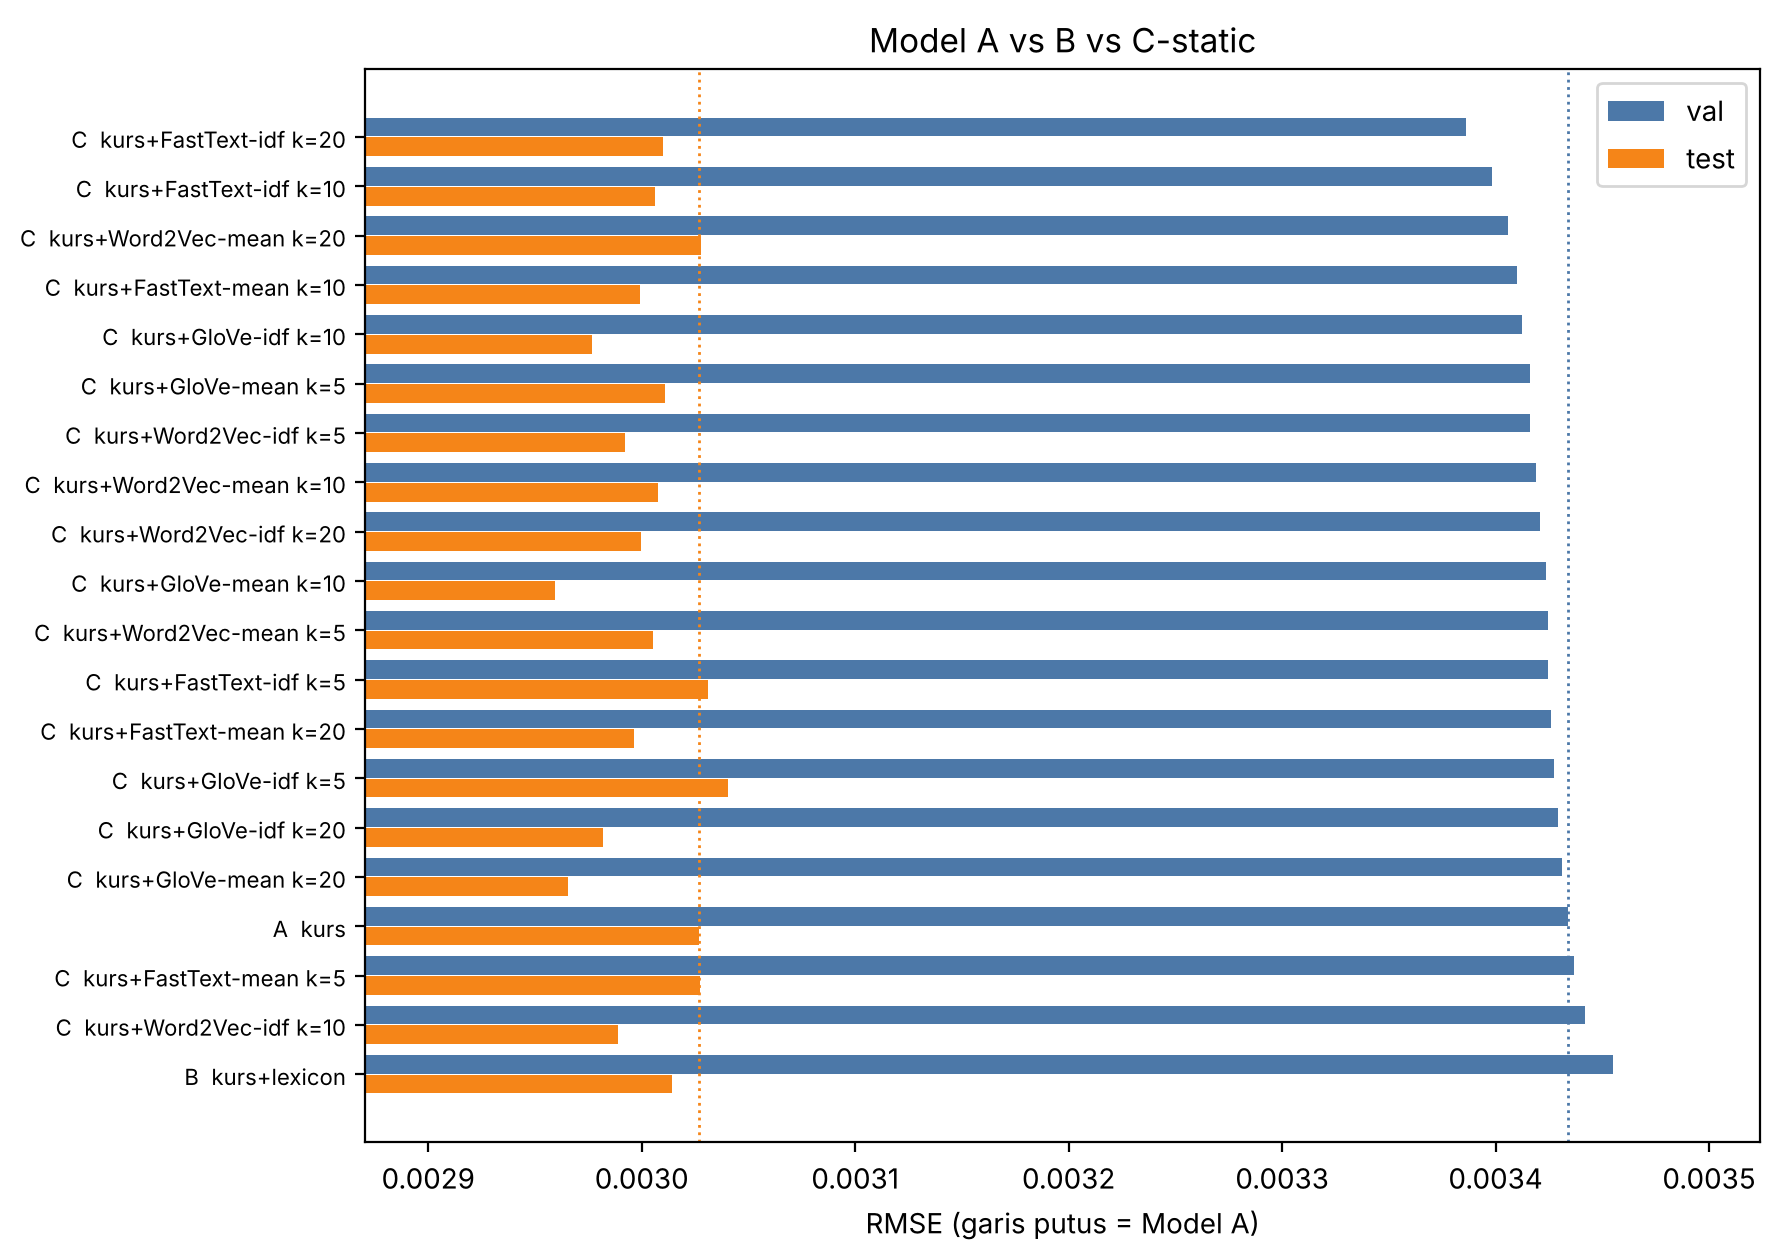

In [12]:
plot_df = mean_tbl["RMSE"].sort_values("val", ascending=False)
fig, ax = plt.subplots(figsize=(9, max(4, 0.32 * len(plot_df))))
yy = np.arange(len(plot_df))
ax.barh(yy + 0.2, plot_df["val"], height=0.38, label="val", color="#4C78A8")
ax.barh(yy - 0.2, plot_df["test"], height=0.38, label="test", color="#F58518")
ax.axvline(a_rmse["val"], color="#4C78A8", ls=":", lw=1); ax.axvline(a_rmse["test"], color="#F58518", ls=":", lw=1)
ax.set_yticks(yy); ax.set_yticklabels(plot_df.index, fontsize=8)
lo = plot_df.min().min() * 0.97; hi = plot_df.max().max() * 1.02
ax.set_xlim(lo, hi); ax.set_xlabel("RMSE (garis putus = Model A)")
ax.legend(); ax.set_title("Model A vs B vs C-static"); plt.tight_layout(); plt.show()

## 7. Cek efek k dan pembobotan (ringkas)
Apakah menambah dimensi PCA atau memakai IDF mengubah gambarnya? Nilai = RMSE val rata-rata 3 model.

In [13]:
c = res[(res["split"] == "val") & res["set"].str.startswith("C")].copy()
c["sumber"] = c["set"].str.extract(r"kurs\+(\w+)-")[0]
c["bobot"] = c["set"].str.extract(r"-(mean|idf)")[0]
c["k"] = c["set"].str.extract(r"k=(\d+)")[0].astype(int)
grid = c.groupby(["sumber", "bobot", "k"])["RMSE"].mean().unstack("k")
grid["A (acuan)"] = a_rmse["val"]
grid.round(6)

k                      5        10        20  A (acuan)
sumber   bobot                                         
FastText idf    0.003425  0.003398  0.003386   0.003434
         mean   0.003437  0.003410  0.003426   0.003434
GloVe    idf    0.003427  0.003412  0.003429   0.003434
         mean   0.003416  0.003424  0.003431   0.003434
Word2Vec idf    0.003416  0.003442  0.003421   0.003434
         mean   0.003424  0.003419  0.003406   0.003434

## 8. Catatan metodologi (untuk laporan)

- **Tidak ada kebocoran:** scaler, IDF, PCA, dan Word2Vec/FastText hanya memakai artikel/hari train. GloVe pretrained tidak pernah melihat data kita.
- **Hari tanpa berita** diisi vektor netral, bukan dibuang, agar deret waktunya tetap utuh.
- **Rata-rata kata** membuang urutan kata dan konteks. Itulah batas utama embedding statis dan alasan perbandingan dengan model kontekstual (Bagian B: FinBERT, MiniLM, dll.).
- Perbedaan RMSE antar set biasanya di orde < 1-2%. Anggap tidak berarti kecuali **konsisten** di val dan test dan di ketiga model.

## 9. Kesimpulan 
1. Apakah B (lexicon) mengalahkan A? Berapa ΔRMSE% di val dan test?
B vs A: tidak ada gain. Di val B sedikit lebih buruk (+0,61%) dan di test sedikit lebih baik (−0,43%). Arahnya bolak-balik, jadi noise.

2. Apakah ada C-static yang konsisten lebih baik dari A dan B di val **dan** test? beberapa set C lebih baik dari A di kedua split (misalnya dua baris di tabel), tapi selisihnya cuma sekitar 0,5–1,7%. Set lain malah lebih buruk di test (FastText-idf k=5, GloVe-idf k=5). Dan "terbaik dari 20 set" pasti tampak bagus karena kebetulan.

3. Mana yang lebih baik: GloVe (pretrained) atau Word2Vec/FastText (domain, korpus kecil)? Mean atau IDF?
tidak ada pola jelas. FastText-idf paling rendah di k=10 dan 20, tapi selisihnya sangat kecil.

4. Apakah BalAcc/MCC di atas 0,5 / 0, atau hanya mengikuti proporsi hari naik?
A di val 0,49 / −0,03. C terbaik di val 0,53 / 0,06 dan di test 0,51 / 0,02. Semuanya mendekati 0,5 / 0, jadi hampir tidak ada kemampuan menebak arah.

Kesimpulan Bagian A: embedding statis tidak memperbaiki prediksi, dan fitur kurs pun belum mengalahkan tebakan konstan.